<a href="https://colab.research.google.com/github/Abigael-Chemutai/Machine_Learning/blob/main/CALIFORNIA_HOUSING_DATA_1990.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CALIFORNIA HOUSING DATA as by the Hands_on book by Aurelien

In [1]:
import sys

assert sys.version_info >= (3, 7)


In [2]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

IMPORT THE DATA FROM GITHUB

In [5]:
import zipfile
from pathlib import Path
import urllib.request
import pandas as pd

def load_california_data():
    zip_path = Path("datasets/California.zip")
    if not zip_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/Abigael-Chemutai/Machine_Learning/raw/refs/heads/main/California.zip"
        urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(path="datasets")
    return pd.read_csv(Path("datasets/California/housing.csv"))

housing = load_california_data()

DIAGNOSTIC CODE TO FIND EXACTLY WHERE THE DATA WAS DOWNLOADED AND EXTRACTED TO AND WHAT IS IN THE DATASETS. NOT IMPORTANT TO THE CODE BUT I USED IT HERE TO HELP ME.


In [4]:
from pathlib import Path
import zipfile

zip_path = Path("datasets/California.zip")
print("Zip exists:", zip_path.is_file())
print("Is valid zip:", zipfile.is_zipfile(zip_path))

with zipfile.ZipFile(zip_path) as z:
    print("Contents:", z.namelist())

print("\nWhat's actually in datasets/:")
for p in Path("datasets").rglob("*"):
    print(p)

Zip exists: True
Is valid zip: True
Contents: ['California/', 'California/housing.csv']

What's actually in datasets/:
datasets/California
datasets/California.zip
datasets/California/housing.csv


In [7]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


The info() method is useful to get a quick description of the data, in
particular the total number of rows, each attribute’s type, and the number of
non-null values:

1. All attributes are numerical, except the ocean_proximity field. Its type
is object
2. total_bedrooms attribute has only 20,433 non-null values, meaningthat 207 districts are missing this feature.

In [8]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [9]:
housing["ocean_proximity"].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


In [10]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


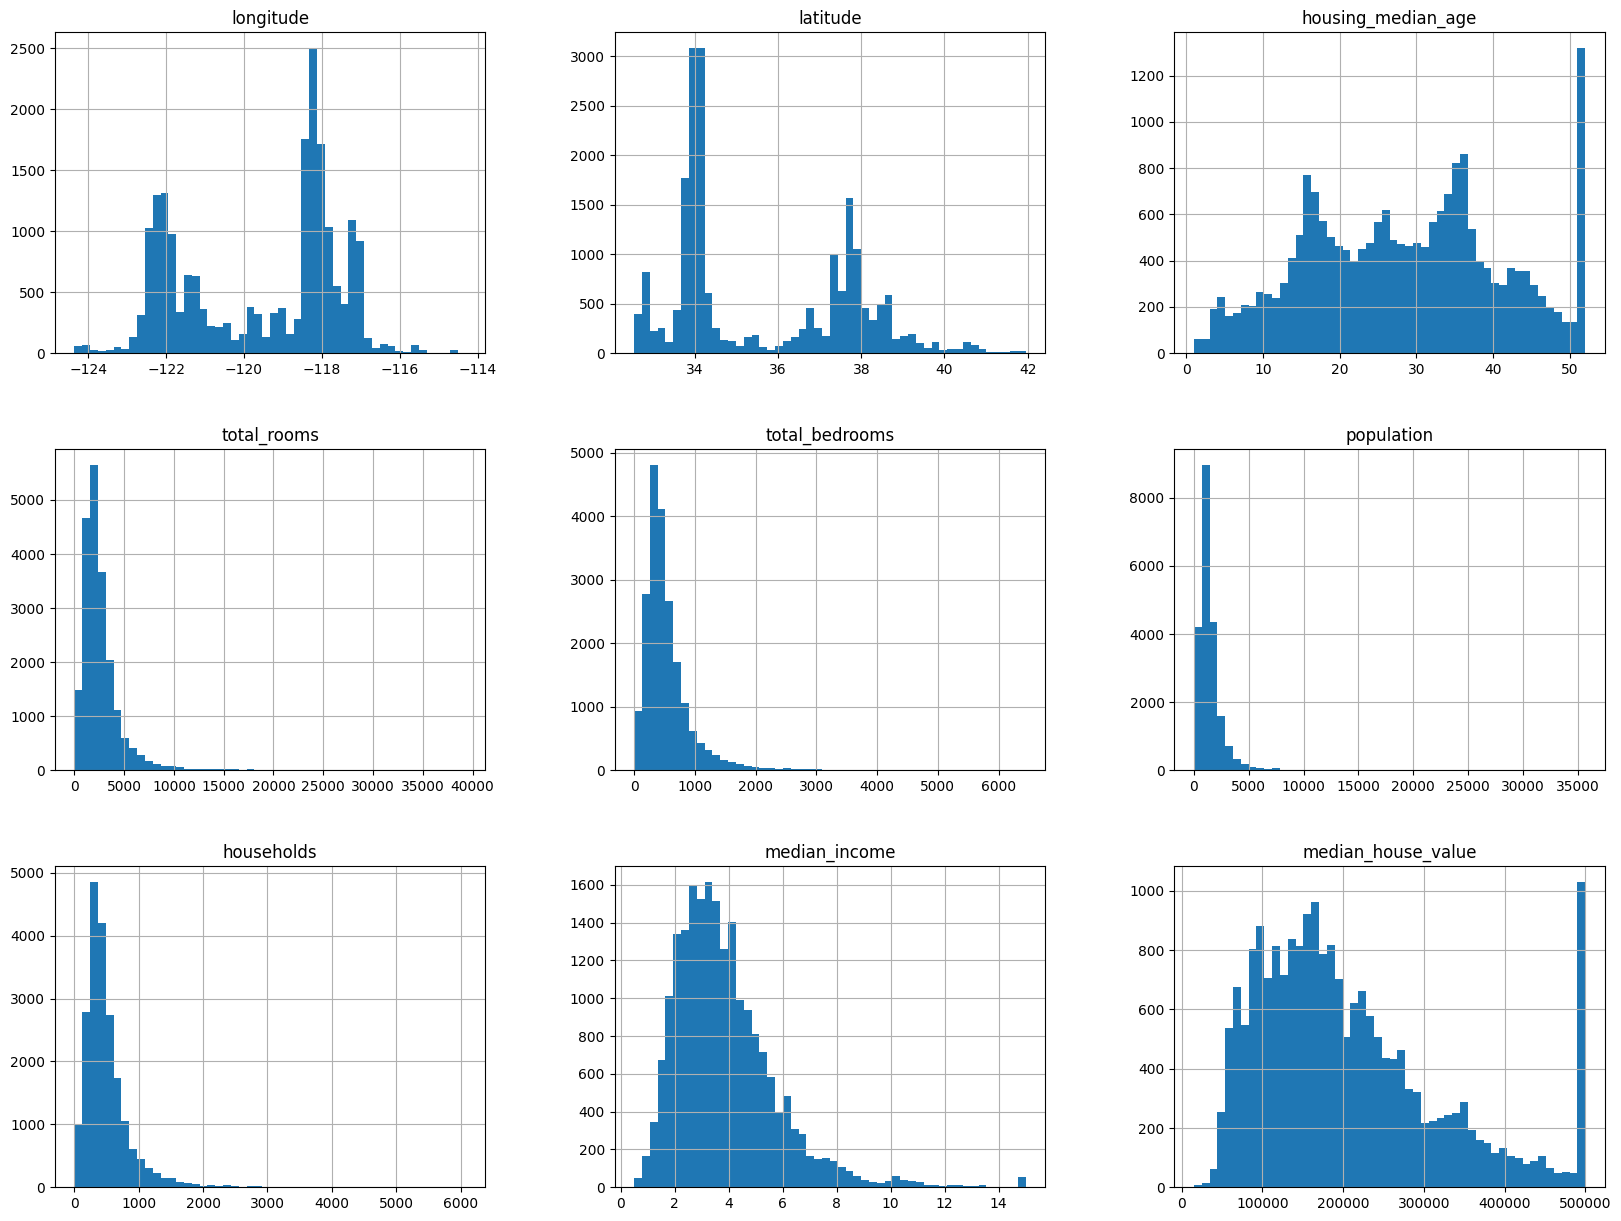

In [11]:
import matplotlib.pyplot as plt
housing.hist(bins=50, figsize=(20,15))
plt.show()

CREATING A TEST SET


In [12]:
import numpy as np

def shuffle_and_split_data(data, test_ratio):
    shuffled_indices = np.random.permutation(len(data))
    # Generates a randomly shuffled array of integers from 0 to len(data)-1.
    # This gives you a random ordering of row indices without modifying the original data.

    test_set_size = int(len(data) * test_ratio)
    # Calculates how many rows should go into the test set,
    # based on the fraction specified by test_ratio (e.g. 0.2 for 20%).
    # int() truncates to a whole number since you can't have a fractional row count.

    test_indices = shuffled_indices[:test_set_size]
    # Takes the first `test_set_size` indices from the shuffled array
    # to use as the test set's row positions.

    train_indices = shuffled_indices[test_set_size:]
    # Takes the remaining indices (everything after the first test_set_size)
    # to use as the training set's row positions.

    return data.iloc[train_indices], data.iloc[test_indices]
    # Uses .iloc to select rows by their integer position,
    # returning (train_data, test_data) as a tuple.

In [13]:
train_set, test_set = shuffle_and_split_data(housing, 0.2)
len(train_set)

16512

In [14]:
len(test_set)

4128

To ensure that this notebook's outputs remain the same every time we run it, we need to set the random seed:


In [15]:
np.random.seed(42)

Sadly, this won't guarantee that this notebook will output exactly the same results as in the book, since there are other possible sources of variation. The most important is the fact that algorithms get tweaked over time when libraries evolve. So please tolerate some minor differences: hopefully, most of the outputs should be the same, or at least in the right ballpark.

Note: another source of randomness is the order of Python sets: it is based on Python's hash() function, which is randomly "salted" when Python starts up (this started in Python 3.3, to prevent some denial-of-service attacks). To remove this randomness, the solution is to set the PYTHONHASHSEED environment variable to "0" before Python even starts up. Nothing will happen if you do it after that. Luckily, if you're running this notebook on Colab, the variable is already set for you.


In [16]:
from zlib import crc32

def is_id_in_test_set(identifier, test_ratio):
    return crc32(np.int64(identifier)) < test_ratio * 2**32

def split_data_with_id_hash(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: is_id_in_test_set(id_, test_ratio))
    return data.loc[~in_test_set], data.loc[in_test_set]

In [17]:
housing_with_id = housing.reset_index()  # adds an `index` column
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "index")

In [18]:
housing_with_id["id"] = housing["longitude"] * 1000 + housing["latitude"]
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "id")

In [19]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)

In [20]:
test_set["total_bedrooms"].isnull().sum()

np.int64(207)

Stratified Sampling

Stratified sampling is a probability method where researchers divide a population into distinct, non-overlapping subgroups (strata) based on shared traits like age or income. Random samples are then drawn from each stratum to ensure key demographics are accurately represented, reducing sampling error compared to simple random sampling.

In [21]:
housing["income_cat"] = pd.cut(housing["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                               labels=[1, 2, 3, 4, 5])

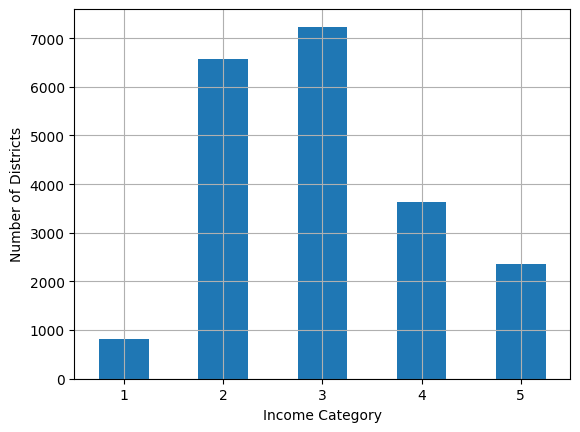

In [23]:
housing["income_cat"].value_counts().sort_index().plot.bar(rot=0, grid=True)
plt.xlabel("Income Category")
plt.ylabel("Number of Districts")
#save_fig("housing_income_cat_bar_plot")
plt.show()

In [24]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)
strat_splits=[]
for train_index,test_index in splitter.split(housing,housing["income_cat"]):
    strat_train_set = housing.loc[train_index]
    strat_test_set = housing.loc[test_index]
    strat_splits.append([strat_train_set,strat_test_set])

In [25]:
strat_train_set, strat_test_set= strat_splits[0]

Since stratified sampling is fairly common, there’s a shorter way to get a
single split using the train_test_split() function with the
stratify argument:


In [26]:
strat_train_set,strat_test_set= train_test_split(housing, test_size=0.2, stratify=housing["income_cat"],
                                                 random_state=42)

In [27]:
strat_test_set["income_cat"].value_counts()/len(strat_test_set)

,count
income_cat,
3,0.350533
2,0.318798
4,0.176357
5,0.114341
1,0.039971


the test set
generated using stratified sampling has income category proportions almost
identical to those in the full dataset, whereas the test set generated using
purely random sampling is skewed.

In [28]:
def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)

train_set, test_set = train_test_split(housing, test_size=0.2, random_state=42)

compare_props = pd.DataFrame({
    "Overall %": income_cat_proportions(housing),
    "Stratified %": income_cat_proportions(strat_test_set),
    "Random %": income_cat_proportions(test_set),
}).sort_index()
compare_props.index.name = "Income Category"
compare_props["Strat. Error %"] = (compare_props["Stratified %"] /
                                   compare_props["Overall %"] - 1)
compare_props["Rand. Error %"] = (compare_props["Random %"] /
                                  compare_props["Overall %"] - 1)
(compare_props * 100).round(2)

,Overall %,Stratified %,Random %,Strat. Error %,Rand. Error %
Income Category,,,,,
1,3.98,4.00,4.02,0.36,0.97
2,31.88,31.88,32.44,-0.02,1.73
3,35.06,35.05,35.85,-0.01,2.27
4,17.63,17.64,16.74,0.03,-5.06
5,11.44,11.43,10.95,-0.08,-4.32


Removing the income_cat column

In [29]:
for set_ in(strat_train_set,strat_test_set): set_.drop("income_cat",axis=1,inplace=True)

Discover and Visualize the Data to Gain
Insights

In [30]:
housing= strat_train_set.copy()

Visualising the geographical data

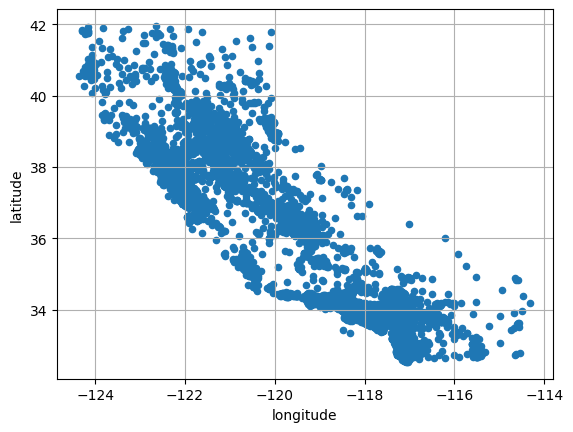

In [31]:
housing.plot(kind="scatter",x="longitude",y="latitude", grid=True)
#save_fig("bad_visualization_plot")
plt.show()

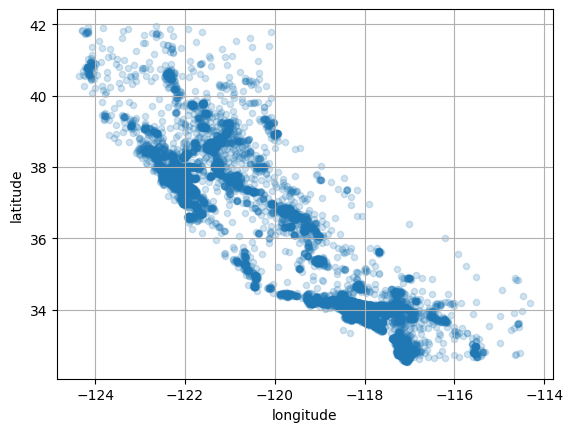

In [32]:
housing.plot(kind="scatter",x="longitude",y="latitude", grid=True, alpha=0.2)
#save_fig("bad_visualization_plot")
plt.show()

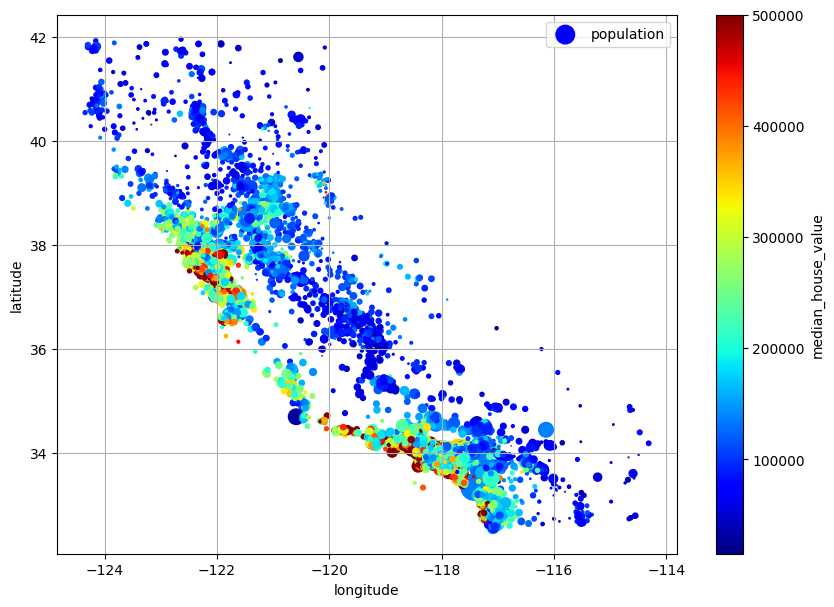

In [35]:
housing.plot(kind="scatter", x="longitude", y="latitude", grid=True,
             s=housing["population"]/100,
             label="population", c="median_house_value",
             cmap="jet", colorbar=True, legend=True, sharex=False, figsize=(10,7))
plt.show()

#The radius of each circle represents the district’s population (option s)
#the color represents the price (option c).

The argument sharex=False fixes a display bug: without it, the x-axis values and label are not displayed (see: https://github.com/pandas-dev/pandas/issues/10611).

The next cell generates the first figure in the chapter (this code is not in the book). It's just a beautified version of the previous figure, with an image of California added in the background, nicer label names and no grid.

In [40]:

# Download the California image
filename = "california.png"
if not (IMAGES_PATH / filename).is_file():
    homl3_root = "https://github.com/Abigael-Chemutai/Machine_Learning/raw/refs/heads/main/california.png"
    url = homl3_root + "images/end_to_end_project/" + filename
    print("Downloading", filename)
    urllib.request.urlretrieve(url, IMAGES_PATH / filename)

housing_renamed = housing.rename(columns={
    "latitude": "Latitude", "longitude": "Longitude",
    "population": "Population",
    "median_house_value": "Median house value (ᴜsᴅ)"})
housing_renamed.plot(
             kind="scatter", x="Longitude", y="Latitude",
             s=housing_renamed["Population"] / 100, label="Population",
             c="Median house value (ᴜsᴅ)", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10, 7))

california_img = plt.imread(IMAGES_PATH / filename)
axis = -124.55, -113.95, 32.45, 42.05
plt.axis(axis)
plt.imshow(california_img, extent=axis)

save_fig("california_housing_prices_plot")
plt.show()

NameError: name 'IMAGES_PATH' is not defined

Looking For Correlations
The correlation coefficient ranges from –1 to 1. When it is close to 1, it
means that there is a strong positive correlation; for example, the median
house value tends to go up when the median income goes up. When the
coefficient is close to –1, it means that there is a strong negative correlation;

In [38]:
corr_matrix=housing.corr(numeric_only=True)

In [39]:
corr_matrix["median_house_value"].sort_values(ascending=False)

,median_house_value
median_house_value,1.000000
median_income,0.687151
total_rooms,0.135140
housing_median_age,0.114146
households,0.064590
total_bedrooms,0.047781
population,-0.026882
longitude,-0.047466
latitude,-0.142673
